# Exp 7 — Paper GridNavi WTE: 5×5 vs 10×10

TaskDist 7 / 8: all goals except the start neighborhood, sparse reward (`+1` / `−0.1`).
- **TD7:** 5×5, H=15, 21 goals, N=375
- **TD8:** 10×10, H=30, 96 goals, N=3000

WTE data is collected from every cell. Mean pairwise cosine uses each dist’s file-length `N` with a shared Detect reference `R`.

In [5]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

SCRIPTS_DIR = CODE_DIR / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from environments.gridworld import GridNavi
from detect import Detect

from plotting import heatmap, annotate_heatmap
from stable_baselines3 import PPO
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from matplotlib.patches import Rectangle

ACTION_NAMES = {0: "noop", 1: "up", 2: "right", 3: "down", 4: "left"}

In [6]:
# defining one task distribution by defining an array of possible goals -

def goal_positions(option, NUM_CELLS):
    if option == 1:
        # 4 goal choices, all in top right corner
        pos = [(NUM_CELLS-1, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-2), (NUM_CELLS-2, NUM_CELLS-1), (NUM_CELLS-2, NUM_CELLS-2)]
    elif option == 2:
        # slightly more spread out
        pos = [(NUM_CELLS//2, NUM_CELLS//2), (NUM_CELLS-1, NUM_CELLS//2), (NUM_CELLS//2, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-1)]
    elif option == 3:
        # goals are all 4 corners
        pos = [(0, 0), (0, NUM_CELLS-1), (NUM_CELLS-1, 0), (NUM_CELLS-1, NUM_CELLS-1)]
    elif option == 4:
        # 4 goal choices in the bottom left corner
        pos = [(0, 0), (0, 1), (1, 0), (1, 1)]
    elif option == 5:
        # 4 goal choices in the top left corner
        pos = [(0, NUM_CELLS-1), (0, NUM_CELLS-2), (1, NUM_CELLS-1), (1, NUM_CELLS-2)]
    elif option == 6:
        # 4 goal choices in the bottom right corner
        pos = [(NUM_CELLS-1, 0), (NUM_CELLS-1, 1), (NUM_CELLS-2, 0), (NUM_CELLS-2, 1)]
    elif option == 7:
        pos = [(i, j) for i in range(NUM_CELLS) for j in range(NUM_CELLS)]
        pos.remove((0, 0))
        pos.remove((0, 1))
        pos.remove((1, 0))
        pos.remove((1, 1))
    return pos


In [7]:
# NUM_CELLS = 10
# MAX_STEPS = 50
# N = NUM_CELLS * NUM_CELLS * MAX_STEPS
SEED = 42

def collect_tuples(task_dists, seed=SEED, distance_reward=True, num_cells=10, max_steps=50):
    """task_dists: dict {dist_id: list of goals}, e.g. {1: task_dist1, 4: task_dist4}.

    distance_reward=True  → dense Manhattan (ours)
    distance_reward=False → paper sparse (−0.1 / step, +1 on goal)
    """
    N = num_cells * num_cells * max_steps
    rng = np.random.default_rng(seed)
    for dist_id, task_dist in task_dists.items():
        OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
        OUT_DIR.mkdir(parents=True, exist_ok=True)

        for task in task_dist:
            sar_rows = []
            for j in range(num_cells):
                for k in range(num_cells):

                    env = GridNavi(
                        num_cells=num_cells,
                        num_steps=max_steps,
                        distance_reward=distance_reward,
                        starting_state=(j, k),
                        possible_goals=task_dist,
                    )
                    env.reset_task(task=task)
                    obs, _ = env.reset()

                    for _ in range(max_steps):
                        action = int(rng.integers(env.action_space.n))
                        next_obs, reward, terminated, truncated, info = env.step(action)
                        sar_rows.append([obs[0], obs[1], action, reward, next_obs[0], next_obs[1]])
                        obs = next_obs
                        if terminated or truncated:
                            obs, _ = env.reset()

            sar = np.array(sar_rows[:N])  # (N, 6): [x, y, action, reward, x', y']
            np.save(OUT_DIR / f"goal_{task[0]}_{task[1]}.npy", sar)


def mean_pairwise_wte(dist_id, goals, num_samples=None):
    """Mean pairwise cosine distance of WTE/LWE embeddings within one task dist.

    If num_samples is set, detect.num_samples is updated first (reference R unchanged).
    Use each dist's file length: 5x5→375, 10x10→3000.
    """
    if num_samples is not None:
        detect.set_num_samples(int(num_samples))
    OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
    embeddings = []
    file_lens = []
    for goal in goals:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        file_lens.append(len(sar))
        embeddings.append(np.asarray(detect.lwe(sar, ACTION_DIM)).ravel())
    E = np.stack(embeddings)
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    E = E / np.clip(norms, 1e-12, None)
    # upper triangle of pairwise cosine distances
    sims = E @ E.T
    iu = np.triu_indices(len(E), k=1)
    cos_dists = 1.0 - sims[iu]
    return {
        "mean_pairwise": float(np.mean(cos_dists)),
        "std_pairwise": float(np.std(cos_dists)),
        "n_goals": int(len(E)),
        "n_pairs": int(len(cos_dists)),
        "file_len": int(file_lens[0]),
        "detect_num_samples": int(detect.get_num_samples()),
    }


In [8]:
# task_dists = {
#     1: goal_positions(1, NUM_CELLS),
#     2: goal_positions(2, NUM_CELLS),
#     3: goal_positions(3, NUM_CELLS),
#     # 4: goal_positions(4, NUM_CELLS),
#     # 5: goal_positions(5, NUM_CELLS),
#     # 6: goal_positions(6, NUM_CELLS),
# }

task_dist1 = {
    7: goal_positions(7, 5),
}
task_dist2 = {
    8: goal_positions(7, 10),
}

# collect sars tuples for each task distribution (dense Manhattan)
collect_tuples(task_dist1, num_cells=5, max_steps=15, distance_reward=False)
collect_tuples(task_dist2, num_cells=10, max_steps=30, distance_reward=False)

# sparse-reward copies: dense k → sparse (k+6) for k=1..6
# DENSE_TO_SPARSE = {1: 7, 2: 8, 3: 9, 4: 10, 5: 11, 6: 12}
# DENSE_TO_SPARSE = {1: 7, 2: 8, 3: 9}

# for dense_id, sparse_id in DENSE_TO_SPARSE.items():
#     task_dists[sparse_id] = list(task_dists[dense_id])
# collect_tuples({sid: task_dists[sid] for sid in DENSE_TO_SPARSE.values()}, distance_reward=False)


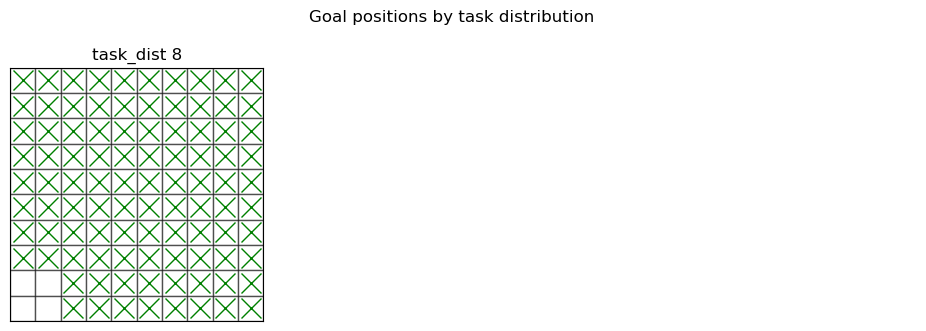

In [14]:
# visualise goal positions for each task distribution
task_dists = task_dist2
NUM_CELLS = 10
MAX_STEPS = 30
N = NUM_CELLS * NUM_CELLS * MAX_STEPS

n = len(task_dists)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (dist_id, goals) in zip(axes, task_dists.items()):
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", alpha=0.5, edgecolor="k"))

    for gx, gy in goals:
        ax.plot(gx + 0.5, NUM_CELLS - gy - 1 + 0.5, "gx", markersize=14, zorder=5)

    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"task_dist {dist_id}")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle("Goal positions by task distribution", y=1.02)
fig.tight_layout()
plt.show()


In [15]:
# setting up the detection object (shared reference R; per-dist N set later)
OBS_DIM = 2
ACTION_DIM = 5
REFERENCE_NUM = 100
VIZ = False

# placeholder num_samples; mean_pairwise_wte(...) sets the correct N per dist
detect = Detect(
        reference_num=REFERENCE_NUM,
        input_dim=OBS_DIM,
        action_dim=ACTION_DIM,
        num_samples=375,
        sars_flag=True,
    )
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)

In [ ]:
# Mean pairwise WTE for TD7 (5x5) and TD8 (10x10), each with its file-length N.
# Same Detect / same reference R; only num_samples changes.

DIST_SPECS = [
    # (dist_id, goals, num_cells, max_steps)
    (7, task_dist1[7], 5, 15),
    (8, task_dist2[8], 10, 30),
]

rows = []
for dist_id, goals, num_cells, max_steps in DIST_SPECS:
    N = num_cells * num_cells * max_steps
    stats = mean_pairwise_wte(dist_id, goals, num_samples=N)
    rows.append({"dist_id": dist_id, "num_cells": num_cells, "max_steps": max_steps, **stats})
    assert stats["file_len"] == N, (dist_id, stats["file_len"], N)
    assert stats["detect_num_samples"] == N, (dist_id, stats["detect_num_samples"], N)
    assert stats["n_goals"] == len(goals), (dist_id, stats["n_goals"], len(goals))
    assert stats["n_pairs"] == len(goals) * (len(goals) - 1) // 2

pw = pd.DataFrame(rows)
display(pw)
print("TD7 vs TD8 mean_pairwise:", float(pw.loc[pw.dist_id == 7, "mean_pairwise"].iloc[0]),
      "vs", float(pw.loc[pw.dist_id == 8, "mean_pairwise"].iloc[0]))

In [16]:
# calculate embeddings of each task in a distribution, and compute their mean
# we then get one vector that represents the task distribution

mean_embeddings = []
dist_ids = []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
    embeddings = []
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = detect.lwe(sar, ACTION_DIM)
        embeddings.append(np.asarray(embedding).ravel())
        if VIZ:
            print(f"-------------------------------- goal: {goal} --------------------------------")
            print("SAR shape:", sar.shape)
            print("Embedding shape:", embedding.shape)
            print("First 5 values:", embedding[:5])
            print("-------------------------------------------------------------------------------")

    mean_embeddings.append(np.mean(np.stack(embeddings), axis=0))
    dist_ids.append(dist_id)

# cosine distance between mean embeddings of each pair of task distributions
V = np.stack(mean_embeddings)
V = V / np.linalg.norm(V, axis=1, keepdims=True)
D = 1.0 - (V @ V.T)
df_mean = (
    pd.DataFrame(D, index=dist_ids, columns=dist_ids)
    .rename_axis("dist")
    .reset_index()
)
print("cosine distances between mean embeddings:")
display(df_mean.round(4))


cosine distances between mean embeddings:


,dist,8
0,8,0.0


In [17]:
mean_dists = []
dist_ids_within = []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
    embeddings = []
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = detect.lwe(sar, ACTION_DIM)
        embeddings.append(np.asarray(embedding).ravel())
        if VIZ:
            print(f"-------------------------------- goal: {goal} --------------------------------")
            print("SAR shape:", sar.shape)
            print("Embedding shape:", embedding.shape)
            print("First 5 values:", embedding[:5])
            print("-------------------------------------------------------------------------------")

    # mean pairwise cosine distance between embeddings in this distribution
    E = np.stack([np.asarray(e).ravel() for e in embeddings])
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    cos_dists = [
        1 - np.dot(E[a], E[b])
        for a in range(len(E))
        for b in range(a + 1, len(E))
    ]
    mean_dists.append(float(np.mean(cos_dists)))
    dist_ids_within.append(dist_id)

df_within = pd.DataFrame(
    {"dist": dist_ids_within, "d": mean_dists},
)
print("mean pairwise cosine distances within each task distribution:")
display(df_within.round(4))


mean pairwise cosine distances within each task distribution:


,dist,d
0,8,0.0151


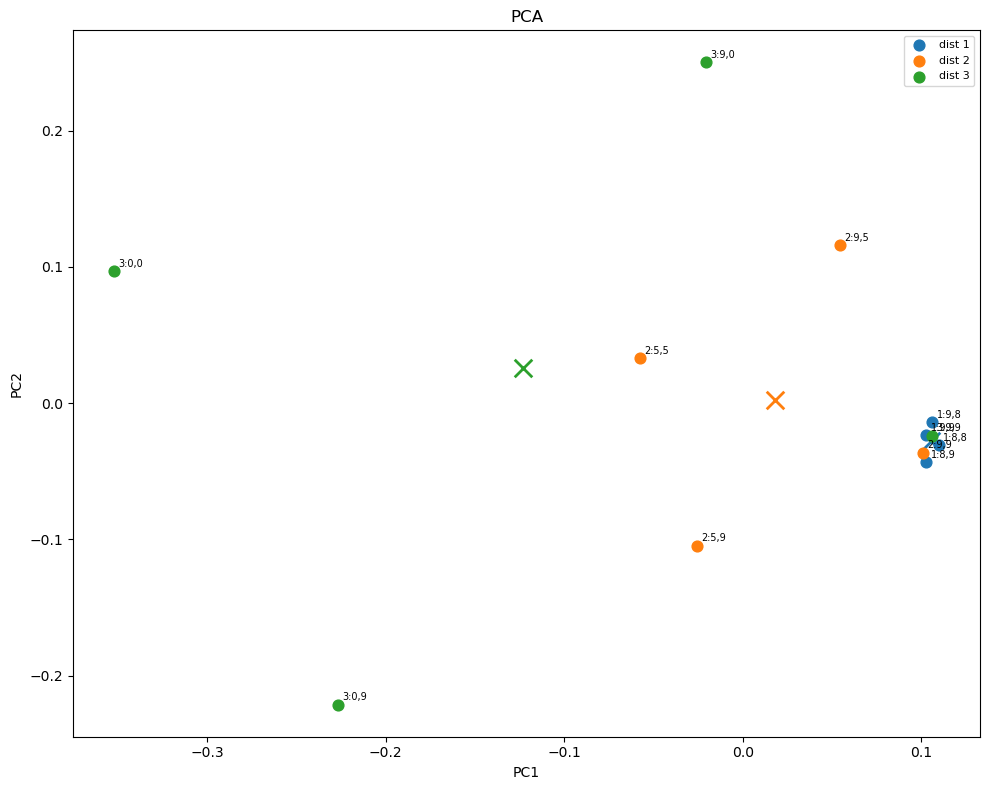

In [9]:
# PCA visualizations of task embeddings

rows, labels, goals = [], [], []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        emb = np.asarray(detect.lwe(sar, ACTION_DIM)).ravel()
        rows.append(emb)
        labels.append(dist_id)
        goals.append(goal)

X = np.stack(rows)  # (n_goals_total, Md)
labels = np.asarray(labels)

X_n = X / np.linalg.norm(X, axis=1, keepdims=True)

Z = PCA(n_components=2, random_state=0).fit_transform(X_n)

fig, ax = plt.subplots(figsize=(10, 8))
for dist_id in sorted(set(labels.tolist())):
    mask = labels == dist_id
    sc = ax.scatter(Z[mask, 0], Z[mask, 1], s=60, label=f"dist {dist_id}")
    color = sc.get_facecolors()[0]
    ax.scatter(
        Z[mask, 0].mean(),
        Z[mask, 1].mean(),
        s=160,
        marker="x",
        linewidths=2,
        c=[color],
    )
for (x, y), g, d in zip(Z, goals, labels):
    ax.annotate(f"{d}:{g[0]},{g[1]}", (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("PCA")
ax.legend(fontsize=8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()


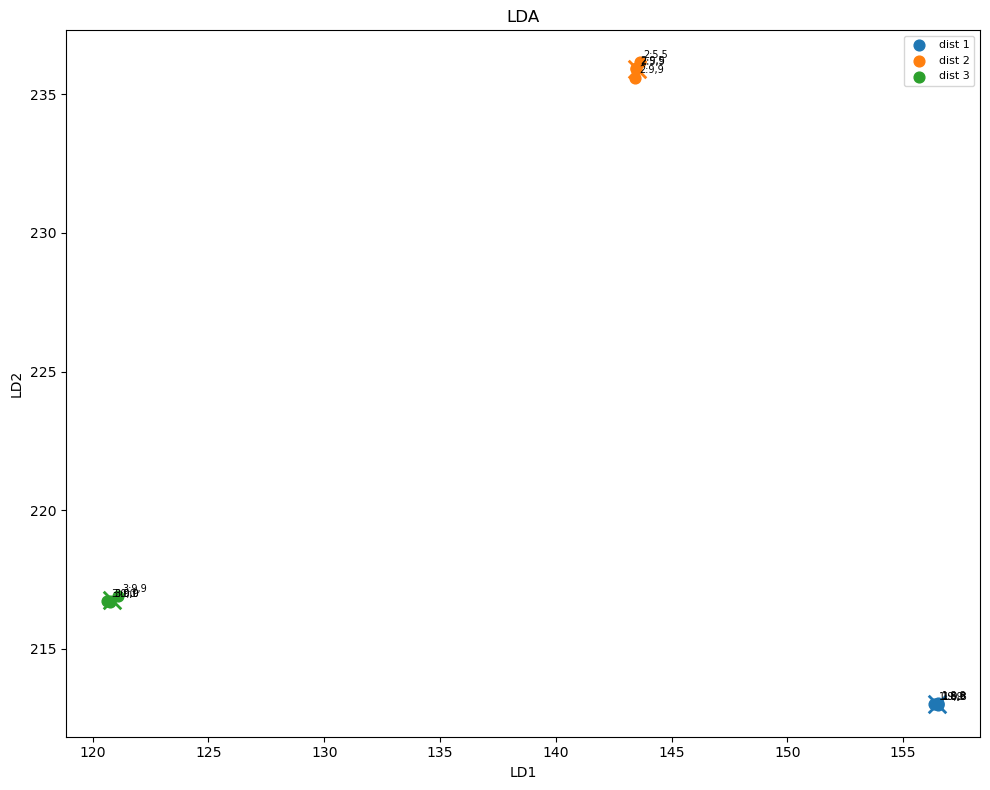

In [10]:
# LDA visualization of task embeddings


n_classes = len(np.unique(labels))
n_components = min(2, n_classes - 1)
# shrinkage helps when dim (800) >> n_samples (~24);
# eigen (not lsqr) supports transform() for 2D projection
lda = LinearDiscriminantAnalysis(
    n_components=n_components, solver="eigen", shrinkage="auto"
)
Z_lda = lda.fit_transform(X_n, labels)

fig, ax = plt.subplots(figsize=(10, 8))
for dist_id in sorted(set(labels.tolist())):
    mask = labels == dist_id
    marker = "^" if dist_id >= 7 else "o"
    sc = ax.scatter(
        Z_lda[mask, 0], Z_lda[mask, 1], s=60, marker=marker, label=f"dist {dist_id}",
    )
    color = sc.get_facecolors()[0]
    ax.scatter(
        Z_lda[mask, 0].mean(),
        Z_lda[mask, 1].mean(),
        s=160,
        marker="x",
        linewidths=2,
        c=[color],
    )
for (x, y), g, d in zip(Z_lda, goals, labels):
    ax.annotate(f"{d}:{g[0]},{g[1]}", (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("LDA")
ax.legend(fontsize=8)
ax.set_xlabel("LD1")
ax.set_ylabel("LD2" if n_components == 2 else "")
fig.tight_layout()
plt.show()


In [11]:
DENSE_TO_SPARSE = {1: 7, 2: 8, 3: 9}

def mean_embedding(dist_id, goals):
    OUT_DIR = CODE_DIR / "data" / f"task_dist{dist_id}"
    embs = [
        np.asarray(detect.lwe(np.load(OUT_DIR / f"goal_{g[0]}_{g[1]}.npy"), ACTION_DIM)).ravel()
        for g in goals
    ]
    return np.mean(np.stack(embs), axis=0)

rows = []
deltas = []
for dense_id, sparse_id in DENSE_TO_SPARSE.items():
    goals = task_dists[dense_id]
    mu_d = mean_embedding(dense_id, goals)
    mu_s = mean_embedding(sparse_id, goals)
    delta = mu_s - mu_d
    deltas.append(delta)
    rows.append(
        {
            "dense": dense_id,
            "sparse": sparse_id,
            "mean_pairwise_dense": mean_pairwise_wte(dense_id, goals)["mean_pairwise"],
            "mean_pairwise_sparse": mean_pairwise_wte(sparse_id, goals)["mean_pairwise"],
            "translation_l2": float(np.linalg.norm(delta)),
        }
    )

D = np.stack(deltas)
D_n = D / np.linalg.norm(D, axis=1, keepdims=True)
# cosine similarity between translation vectors (are shifts parallel?)
cos = D_n @ D_n.T

df_trans = pd.DataFrame(rows)
print("Dense vs sparse: within-dist WTE pairwise + translation L2 of mean embeddings:")
display(df_trans.round(6))

print("Cosine similarity between dense→sparse translation vectors:")
display(pd.DataFrame(cos, index=list(DENSE_TO_SPARSE), columns=list(DENSE_TO_SPARSE)).round(4))
print(f"Mean translation L2: {np.mean([r['translation_l2'] for r in rows]):.6f}  std: {np.std([r['translation_l2'] for r in rows]):.6f}")


Dense vs sparse: within-dist WTE pairwise + translation L2 of mean embeddings:


,dense,sparse,mean_pairwise_dense,mean_pairwise_sparse,translation_l2
0,1,7,0.009652,0.010097,0.927899
1,2,8,0.034620,0.012210,0.758869
2,3,9,0.089683,0.013736,0.817955


Cosine similarity between dense→sparse translation vectors:


,1,2,3
1,1.0000,0.9558,0.7819
2,0.9558,1.0000,0.8417
3,0.7819,0.8417,1.0000


Mean translation L2: 0.834908  std: 0.070040
